# 01 - Data Acquisition & Exploratory Data Analysis

**Project:** CardioRisk - heart disease risk prediction  
**Dataset:** UCI Heart Disease, Cleveland subset (303 patients, 13 features + diagnosis)

This notebook walks through how the data is obtained, cleaned and explored. All the heavy lifting lives in the `heartrisk` package so the same code runs in CI and in the training pipeline; the notebook only calls it and explains the results.

In [1]:
import json
import pandas as pd
from IPython.display import display

from heartrisk.config import load_config, resolve
from heartrisk.data import download, clean
from heartrisk.eda import plots

cfg = load_config()
plots.set_style()
pd.set_option('display.width', 120)

## 1. Data acquisition

`heartrisk.data.download` pulls the official UCI zip, extracts `processed.cleveland.data` and writes a `MANIFEST.json` with the source URL, download time and SHA-256. If the zip endpoint is down it falls back to the direct file link. The checksum lets anyone confirm they trained on exactly the same bytes.

In [2]:
manifest = download.download()
print(json.dumps(manifest, indent=2))

{
  "source": "https://archive.ics.uci.edu/static/public/45/heart+disease.zip",
  "file": "processed.cleveland.data",
  "downloaded_at": "2026-10-17T16:15:40+00:00",
  "bytes": 18461,
  "rows": 303,
  "sha256": "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8"
}


In [3]:
raw = clean.load_raw(resolve(cfg['data']['raw_file']))
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Feature dictionary

| Column | Meaning | Type |
|---|---|---|
| age | Age in years | continuous |
| sex | 1 = male, 0 = female | binary |
| cp | Chest pain type (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic) | nominal |
| trestbps | Resting blood pressure (mm Hg) | continuous |
| chol | Serum cholesterol (mg/dl) | continuous |
| fbs | Fasting blood sugar > 120 mg/dl | binary |
| restecg | Resting ECG (0 normal, 1 ST-T abnormality, 2 LV hypertrophy) | nominal |
| thalach | Maximum heart rate achieved | continuous |
| exang | Exercise-induced angina | binary |
| oldpeak | ST depression induced by exercise | continuous |
| slope | Slope of peak exercise ST segment | nominal |
| ca | Number of major vessels coloured by fluoroscopy (0-3) | ordinal |
| thal | Thallium test (3 normal, 6 fixed defect, 7 reversible defect) | nominal |
| num | Diagnosis, 0 = no disease, 1-4 = increasing severity | target |

## 2. Data quality check

In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


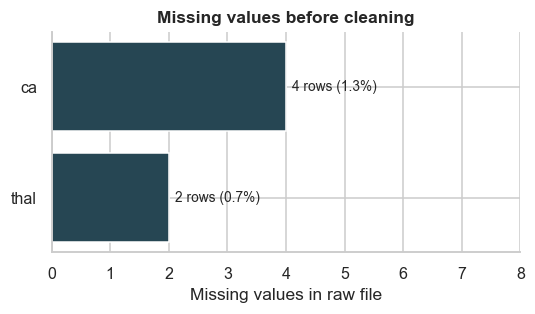

In [6]:
plots.missing_values(raw);

Only **`ca` (4 rows)** and **`thal` (2 rows)** are missing, encoded as `?` in the raw file. That is under 2% of rows, so instead of dropping patients I impute with the **mode** - both are coded categorical columns, so a median could produce a value that is not a valid code.

In [7]:
raw['num'].value_counts().sort_index()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

The original diagnosis ranges 0-4, but the higher grades have very few patients (13 with grade 4). Following the problem statement, I collapse it into a binary target: **0 = no disease, 1 = any disease (num >= 1)**.

## 3. Cleaning

`heartrisk.data.clean` performs these steps and logs each one to `reports/data_quality.json`:

1. Parse `?` as missing.
2. Drop exact duplicate rows.
3. Flag values outside clinically plausible ranges (set in `config/params.yaml`) as missing.
4. Impute - median for continuous columns, mode for coded columns.
5. Binarise the target and cast coded columns to integers.
6. Write `heart_clean.csv` (integer codes) and `heart_encoded.csv` (one-hot nominal columns).

In [8]:
df = clean.run()
print(json.dumps(json.loads(resolve(cfg['data']['quality_report']).read_text()), indent=2))

{
  "rows_in": 303,
  "missing_before": {
    "ca": 4,
    "thal": 2
  },
  "duplicates_removed": 0,
  "out_of_range_flagged": {
    "age": 0,
    "trestbps": 0,
    "chol": 0,
    "thalach": 0,
    "oldpeak": 0
  },
  "imputed": {
    "ca": {
      "rows": 4,
      "value": 0.0
    },
    "thal": {
      "rows": 2,
      "value": 3.0
    }
  },
  "rows_out": 303,
  "class_counts": {
    "0": 164,
    "1": 139
  },
  "missing_after": 0
}


In [9]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


In [10]:
encoded = pd.read_csv(resolve(cfg['data']['encoded_file']))
print(encoded.shape)
encoded.columns.tolist()

(303, 23)


['age',
 'sex',
 'trestbps',
 'chol',
 'fbs',
 'thalach',
 'exang',
 'oldpeak',
 'ca',
 'target',
 'cp_asymptomatic',
 'cp_atypical_angina',
 'cp_non_anginal',
 'cp_typical_angina',
 'restecg_lv_hypertrophy',
 'restecg_normal',
 'restecg_st_t_abnormal',
 'slope_downsloping',
 'slope_flat',
 'slope_upsloping',
 'thal_fixed_defect',
 'thal_normal',
 'thal_reversible_defect']

The encoded file one-hot encodes `cp`, `restecg`, `slope` and `thal` with readable column names (e.g. `cp_asymptomatic`). `ca` stays as an ordinal integer because more blocked vessels genuinely means more risk. Scaling is **not** done here - it belongs inside the model pipeline so it is fitted only on training folds and never leaks information from the test set.

## 4. Exploratory analysis

### 4.1 Class balance

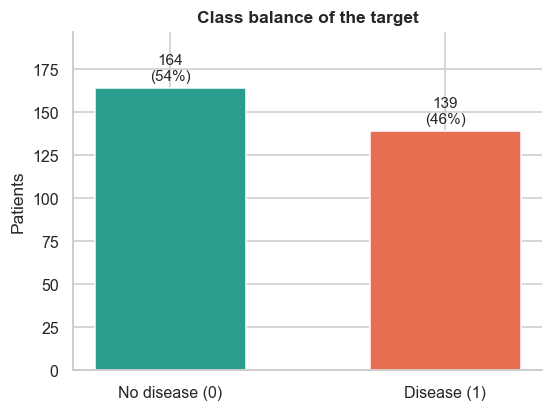

In [11]:
plots.class_balance(df);

164 healthy vs 139 diseased patients (54% / 46%). The classes are close enough that accuracy is meaningful, but I will still report precision, recall and ROC-AUC, and use stratified folds so each split keeps this ratio.

### 4.2 Continuous features

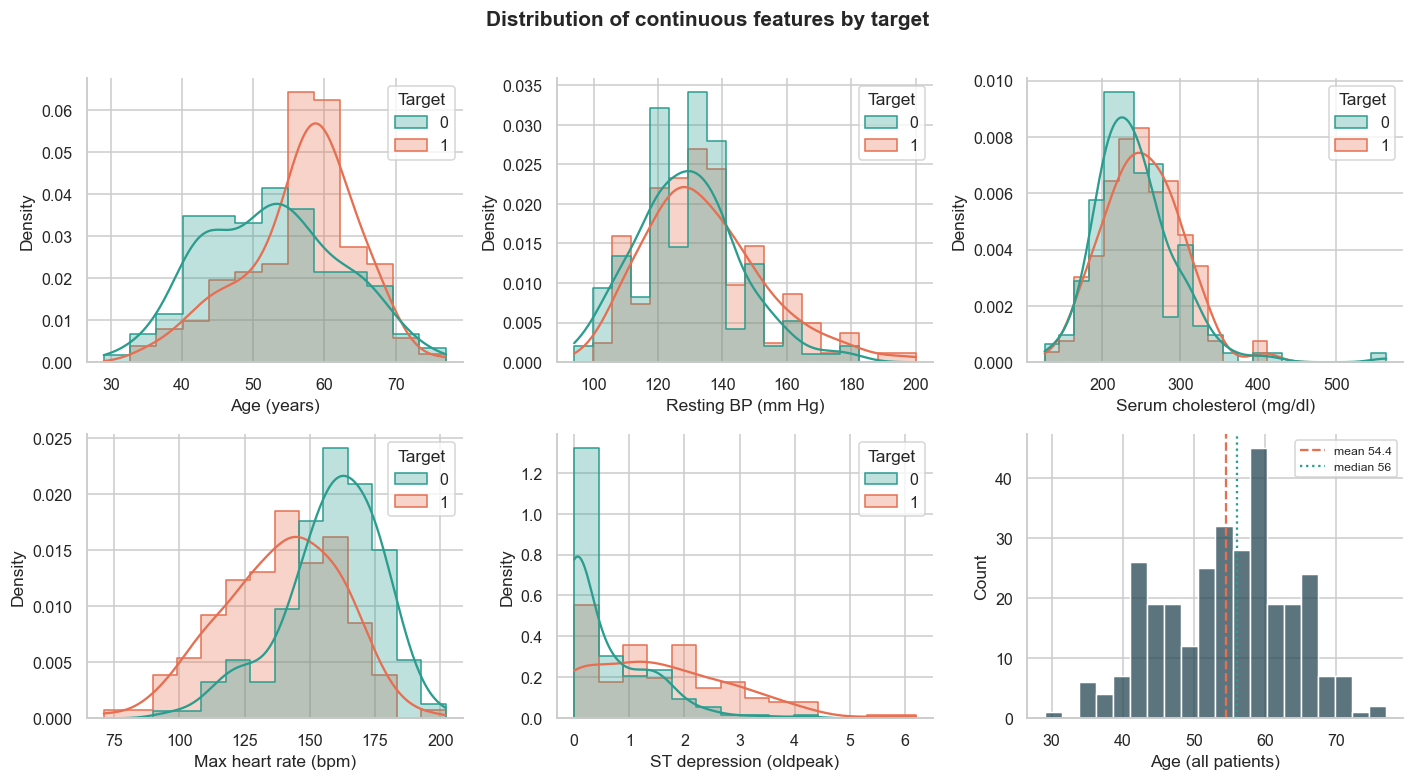

In [12]:
plots.numeric_histograms(df, cfg['columns']['numeric']);

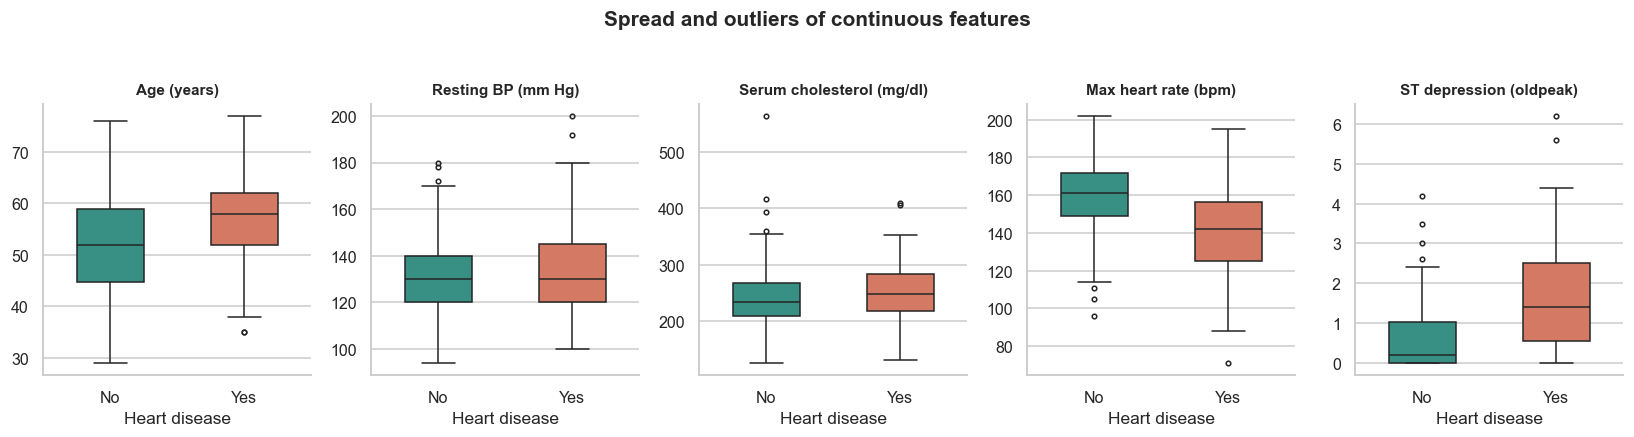

In [13]:
plots.numeric_boxplots(df, cfg['columns']['numeric']);

In [14]:
(df.groupby('target')[cfg['columns']['numeric']].median().T
   .rename(columns={0: 'no disease', 1: 'disease'}))

target,no disease,disease
age,52.0,58.0
trestbps,130.0,130.0
chol,234.5,249.0
thalach,161.0,142.0
oldpeak,0.2,1.4


**Observations**

- **thalach** (max heart rate) is the clearest separator: diseased patients peak around 140 bpm vs ~160 bpm for healthy ones.
- **oldpeak** is heavily right-skewed; most healthy patients sit at 0, while diseased patients spread out to 4+. A log or power transform may help linear models.
- **age** shifts right for the disease group (median 58 vs 52).
- **trestbps** and **chol** overlap heavily - weak signals on their own. Cholesterol has one extreme reading (564 mg/dl); it is high but clinically possible, so I keep it and rely on robust models / scaling rather than deleting it.

### 4.3 Correlations

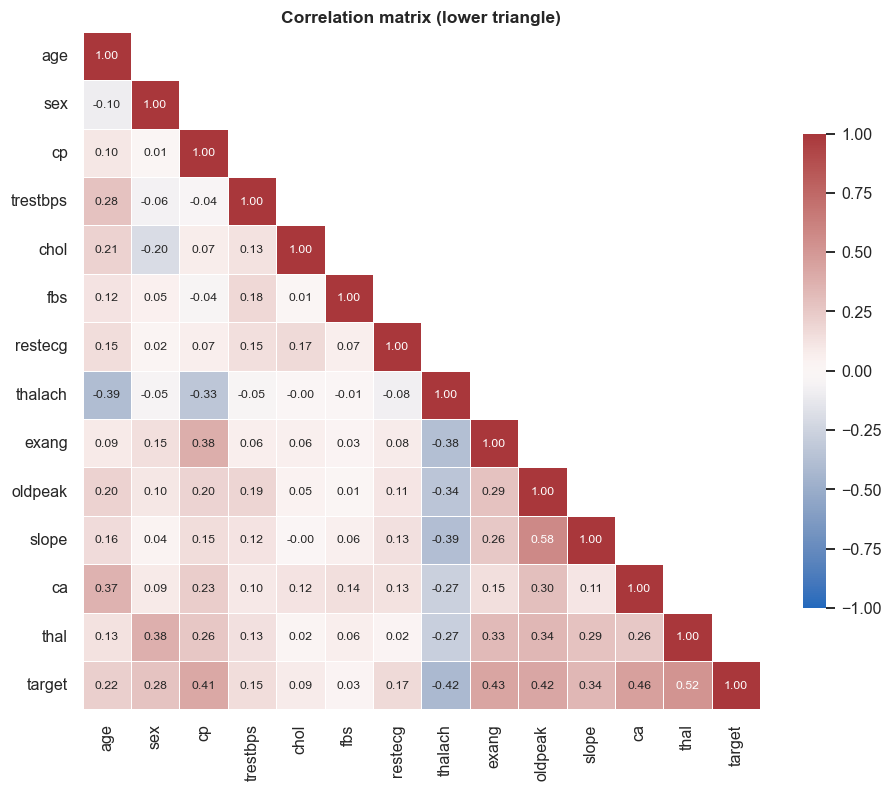

In [15]:
plots.correlation_heatmap(df);

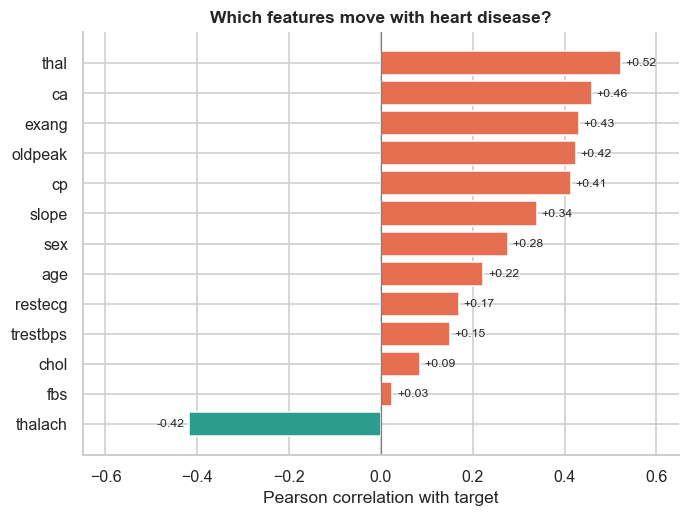

In [16]:
plots.target_correlation(df);

- Strongest links with the target: **thal (0.52), ca (0.46), exang (0.43), oldpeak (0.42), cp (0.41)** and **thalach (-0.42)**.
- `fbs` (0.03) and `chol` (0.09) carry almost no linear signal.
- No pair of features is above 0.6, so multicollinearity is not a serious concern; the largest is `oldpeak`-`slope` (0.58), which makes sense as both describe the ST segment.
- Pearson correlation on nominal codes (`cp`, `thal`) is only indicative - the category-level view below is more honest for them.

### 4.4 Categorical features

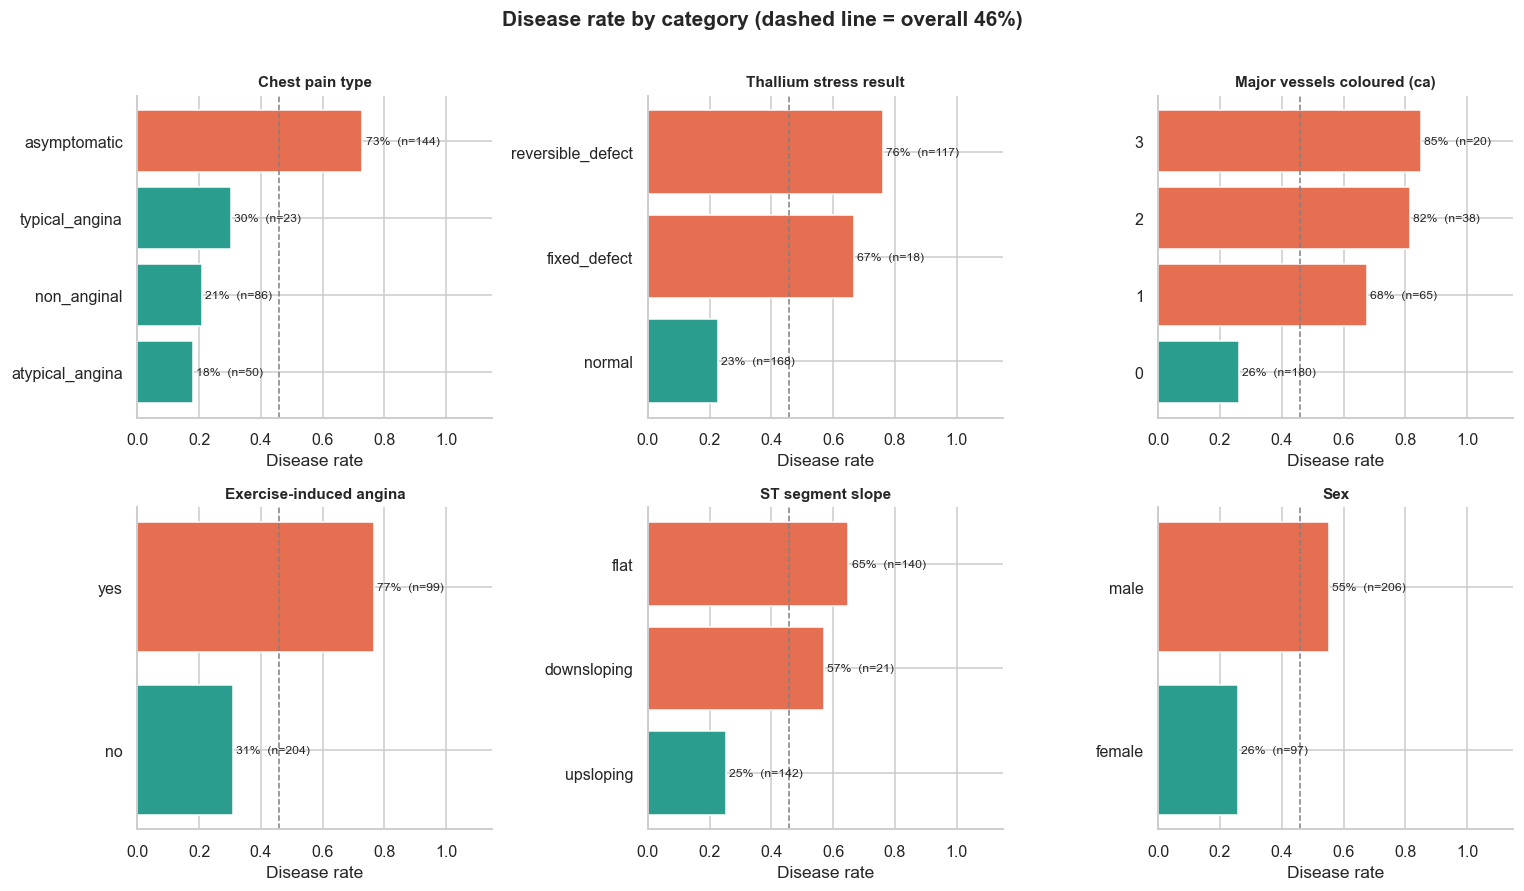

In [17]:
plots.categorical_disease_rate(df, ['cp', 'thal', 'ca', 'exang', 'slope', 'sex']);

- **Asymptomatic chest pain** has a 73% disease rate - counter-intuitive but well known in this dataset: patients without classic angina symptoms were often referred for silent ischaemia.
- A **reversible thallium defect** (76%) and **any coloured vessel** (68-85%) are strong red flags.
- **Exercise-induced angina** more than doubles the rate (77% vs 31%).
- These relationships are not monotonic in the raw codes (e.g. `cp` 1-3 are all low), which is why the nominal columns are one-hot encoded rather than treated as numbers.

### 4.5 Age, sex and heart rate

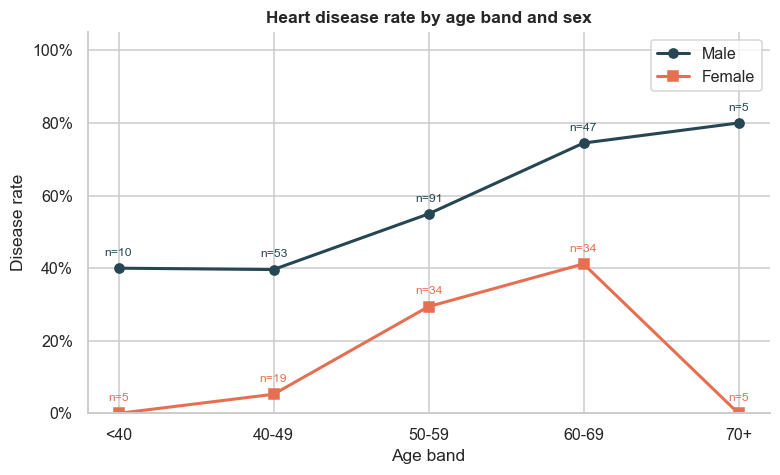

In [18]:
plots.age_band_risk(df);

Risk climbs steadily with age for men, from ~40% under 50 to ~75% in their 60s. Women in this sample have much lower rates at every age band, although the female group is small (97 patients) so the 70+ point (n=5) should not be over-read. This suggests an **age x sex interaction** worth testing during feature engineering.

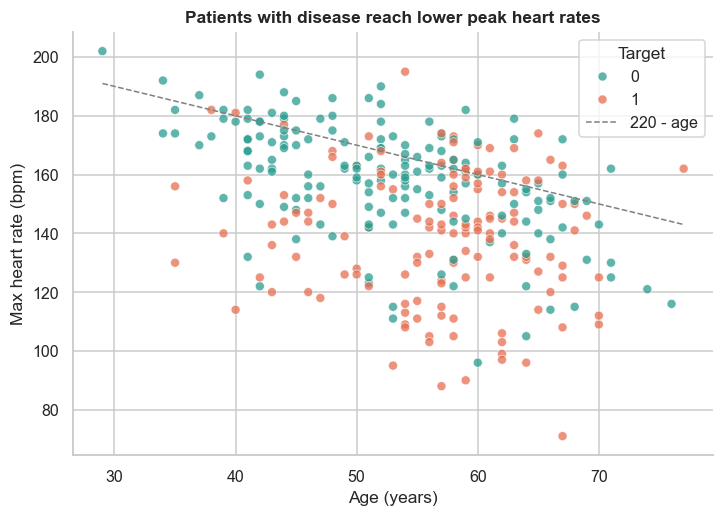

In [19]:
plots.hr_vs_age(df);

Max heart rate falls with age for everyone, but diseased patients sit consistently further below the `220 - age` reference. That gap - **heart-rate reserve** - could be a more informative feature than `thalach` alone, because it adjusts for age.

## 5. Summary and next steps

| Finding | Implication for modelling |
|---|---|
| Only 6 missing cells, all in coded columns | Mode imputation inside the pipeline |
| Classes are 54/46 | Stratified CV; report ROC-AUC, precision, recall |
| `oldpeak` right-skewed | Try a power transform for linear models |
| Nominal codes are non-monotonic | One-hot encode `cp`, `restecg`, `slope`, `thal` |
| `fbs`, `chol` weak | Keep, but check feature importance |
| Heart rate depends on age | Engineer `hr_reserve = thalach / (220 - age)` |
| Risk differs strongly by sex across age | Consider an age-sex interaction |

All figures are saved to `reports/figures/` for the report.

In [20]:
plots.generate_all()
sorted(p.name for p in resolve(cfg['eda']['figures_dir']).glob('*.png'))

['01_class_balance.png',
 '02_missing_values.png',
 '03_numeric_histograms.png',
 '04_numeric_boxplots.png',
 '05_correlation_heatmap.png',
 '06_target_correlation.png',
 '07_categorical_disease_rate.png',
 '08_age_band_risk.png',
 '09_hr_vs_age.png']